In [61]:
import pandas as pd

In [62]:
import numpy as np

# ---------------------------------------------------
# STEP 1: Set file paths
# ---------------------------------------------------

# input_file = "2019-Oct.csv"
# output_file = "ecommerce_random_50000_users.csv"

# # We only read the columns needed for the assignment
# use_cols = [
#     "event_time",
#     "event_type",
#     "product_id",
#     "category_id",
#     "category_code",
#     "brand",
#     "price",
#     "user_id",
#     "user_session"
# ]

# ---------------------------------------------------
# STEP 2: Collect all unique user IDs
# ---------------------------------------------------

# all_users = set()

# print("Collecting unique users...")

# for chunk in pd.read_csv(
#     input_file,
#     usecols=["user_id"],
#     chunksize=500000
# ):
#     users = chunk["user_id"].dropna().unique()
#     all_users.update(users)

# print("Total unique users found:", len(all_users))

# ---------------------------------------------------
# STEP 3: Randomly select 50,000 unique users
# ---------------------------------------------------

# all_users = np.array(list(all_users))

# np.random.seed(42)

# selected_users = np.random.choice(
#     all_users,
#     size=50000,
#     replace=False
# )

# selected_users = set(selected_users)

# print("Randomly selected users:", len(selected_users))

# ---------------------------------------------------
# STEP 4: Read the full file again and keep
#         every event belonging to those users
# ---------------------------------------------------

# selected_chunks = []

# print("Extracting events for selected users...")

# for chunk in pd.read_csv(
#     input_file,
#     usecols=use_cols,
#     chunksize=500000
# ):
#     filtered_chunk = chunk[
#         chunk["user_id"].isin(selected_users)
#     ]

#     if not filtered_chunk.empty:
#         selected_chunks.append(filtered_chunk)

# ---------------------------------------------------
# STEP 5: Combine the selected data
# ---------------------------------------------------

# sample_df = pd.concat(
#     selected_chunks,
#     ignore_index=True
# )

# # ---------------------------------------------------
# # STEP 6: Save the new dataset
# # ---------------------------------------------------

# sample_df.to_csv(
#     output_file,
#     index=False
# )

# ---------------------------------------------------
# STEP 7: Verify the result
# ---------------------------------------------------

# print("\nSampling completed successfully.")
# print("Total rows:", len(sample_df))
# print("Unique users:", sample_df["user_id"].nunique())
# print("Output file:", output_file)

In [63]:
df = pd.read_csv("ecommerce_random_50000_users.csv")

In [64]:
df.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:06:03 UTC,view,4100305,2053013561218695907,NaN,sony,470.02,513573912,c0811104-1194-40f7-92b8-b4c8013f50e5
1,2019-10-01 00:06:07 UTC,view,3600163,2053013563810775923,appliances.kitchen.washer,indesit,179.67,512533331,f67fc5f3-86fb-4dc6-90aa-561781e1c513
2,2019-10-01 00:06:14 UTC,view,3600661,2053013563810775923,appliances.kitchen.washer,samsung,295.49,512533331,f67fc5f3-86fb-4dc6-90aa-561781e1c513
3,2019-10-01 00:06:47 UTC,view,1004870,2053013555631882655,electronics.smartphone,samsung,286.86,534574204,961ff93c-0af2-4319-9535-32f6f3fc08fe
4,2019-10-01 00:07:10 UTC,view,1004836,2053013555631882655,electronics.smartphone,samsung,241.19,534574204,961ff93c-0af2-4319-9535-32f6f3fc08fe


In [65]:
df.tail()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
701560,2019-10-31 23:58:53 UTC,view,16000004,2053013558223962683,NaN,rondell,43.73,516203869,f57ed95e-820f-40ef-ab55-09f87fdf4703
701561,2019-10-31 23:59:31 UTC,view,16000004,2053013558223962683,NaN,rondell,43.73,516203869,f57ed95e-820f-40ef-ab55-09f87fdf4703
701562,2019-10-31 23:59:35 UTC,view,1002524,2053013555631882655,electronics.smartphone,apple,531.26,565404816,d9cf0ac4-c3ec-4e1f-83aa-326b1e7b1581
701563,2019-10-31 23:59:50 UTC,view,13104838,2053013553526341921,NaN,remain,207.98,525530673,58da4d41-bb51-4bc1-99e1-9ae571957fd6
701564,2019-10-31 23:59:52 UTC,view,1002524,2053013555631882655,electronics.smartphone,apple,531.26,565404816,d9cf0ac4-c3ec-4e1f-83aa-326b1e7b1581


In [66]:
df.shape

(701565, 9)

In [67]:
df.columns

Index(['event_time', 'event_type', 'product_id', 'category_id',
       'category_code', 'brand', 'price', 'user_id', 'user_session'],
      dtype='str')

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701565 entries, 0 to 701564
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     701565 non-null  str    
 1   event_type     701565 non-null  str    
 2   product_id     701565 non-null  int64  
 3   category_id    701565 non-null  int64  
 4   category_code  480552 non-null  str    
 5   brand          600077 non-null  str    
 6   price          701565 non-null  float64
 7   user_id        701565 non-null  int64  
 8   user_session   701565 non-null  str    
dtypes: float64(1), int64(3), str(5)
memory usage: 48.2 MB


In [69]:
print("Unique users:", df["user_id"].nunique())
print("Unique sessions:", df["user_session"].nunique())
print("Unique products:", df["product_id"].nunique())
print("Unique categories:", df["category_id"].nunique())
print("Unique category codes:", df["category_code"].nunique())
print("Unique brands:", df["brand"].nunique())

Unique users: 50000
Unique sessions: 152294
Unique products: 61484
Unique categories: 599
Unique category codes: 126
Unique brands: 2461


In [70]:
df.describe()

,product_id,category_id,price,user_id
count,7.015650e+05,7.015650e+05,701565.000000,7.015650e+05
mean,1.054392e+07,2.057498e+18,289.088589,5.337572e+08
std,1.192920e+07,1.870545e+16,356.041927,1.843591e+07
min,1.000978e+06,2.053014e+18,0.000000,2.878734e+08
25%,1.005140e+06,2.053014e+18,66.050000,5.160740e+08
50%,5.000575e+06,2.053014e+18,163.710000,5.300916e+08
75%,1.600105e+07,2.053014e+18,358.260000,5.517320e+08
max,6.050001e+07,2.175420e+18,2574.070000,5.662778e+08


In [71]:
event_counts = df["event_type"].value_counts()

In [72]:
event_percentages = df["event_type"].value_counts(normalize=True) * 100
event_summary = pd.DataFrame({"Count": event_counts, "Percentage": event_percentages})
event_summary

,Count,Percentage
event_type,,
view,672801,95.900024
cart,15922,2.269497
purchase,12842,1.830479


In [73]:
missing_values = pd.DataFrame({"Missing Values": df.isnull().sum(), "Percentage": (df.isnull().sum() / len(df)) * 100})
missing_values

,Missing Values,Percentage
event_time,0,0.000000
event_type,0,0.000000
product_id,0,0.000000
category_id,0,0.000000
category_code,221013,31.502854
brand,101488,14.465944
price,0,0.000000
user_id,0,0.000000
user_session,0,0.000000


Missing values are mainly found in category_code and brand.

In [74]:
df.duplicated().sum()

np.int64(603)

The dataset contains 603 duplicate rows that will be handled during cleaning.

In [75]:
df["price"].describe()

count    701565.000000
mean        289.088589
std         356.041927
min           0.000000
25%          66.050000
50%         163.710000
75%         358.260000
max        2574.070000
Name: price, dtype: float64

Checking zero or negative prices

In [76]:
print("Zero prices:", (df["price"] == 0).sum())
print("Negative prices:", (df["price"] < 0).sum())

Zero prices: 1128
Negative prices: 0


converting the timestamp

In [77]:
df["event_time"] = pd.to_datetime(df["event_time"], utc=True)
df["event_time"].dtype

datetime64[us, UTC]

In [78]:
print("Start date:", df["event_time"].min())
print("End date:", df["event_time"].max())

Start date: 2019-10-01 00:06:03+00:00
End date: 2019-10-31 23:59:52+00:00


In [79]:
df.sample(5, random_state=42)

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
517942,2019-10-23 14:30:59+00:00,view,28716950,2053013565228450757,apparel.shoes,nexpero,110.43,545637297,1aac7888-b188-4789-9268-1eba4d5938c8
230977,2019-10-11 17:09:58+00:00,view,5701084,2053013553970938175,auto.accessories.player,kenwood,131.27,512304685,41defc3a-71ba-4b96-8a25-6dab36311694
610831,2019-10-27 14:46:18+00:00,view,19100417,2053013556227473861,construction.tools.saw,tch,41.18,459349272,12614a38-fa1a-4143-9aa7-2b08c8be0a41
594646,2019-10-27 02:37:31+00:00,view,28720834,2053013565782098913,apparel.shoes,NaN,94.98,512363741,35efa682-ab12-4882-bc9c-3a96b94a8850
206056,2019-10-10 16:24:12+00:00,view,21410925,2053013561579406073,electronics.clocks,NaN,249.17,539350600,ce162c27-1fa9-42b0-8608-01467c9b128f


### Data Cleaning

The dataset is cleaned by removing duplicates, handling missing values, and checking invalid price records before customer-level feature engineering.

In [80]:
# Create a copy before cleaning
df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (701565, 9)


Removing duplicate rows

In [81]:
# Check duplicates before removal
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows before cleaning: 603
Duplicate rows after cleaning: 0
Shape after removing duplicates: (700962, 9)


Exact duplicate event records were removed to avoid overcounting customer activity.

Checking essential missing values

In [82]:
essential_columns = ["event_time", "event_type", "product_id", "category_id", "price", "user_id", "user_session"]
df_clean[essential_columns].isnull().sum()

event_time      0
event_type      0
product_id      0
category_id     0
price           0
user_id         0
user_session    0
dtype: int64

In [83]:
# Remove rows only if essential fields are missing
df_clean = df_clean.dropna(subset=essential_columns)

print("Shape after checking essential missing values:", df_clean.shape)

Shape after checking essential missing values: (700962, 9)


Rows with missing essential fields are removed, while missing category_code and brand values are retained because they are not required for the main clustering features.

Handling missing category and brand values

In [84]:
df_clean["category_code"] = df_clean["category_code"].fillna("Unknown")
df_clean["brand"] = df_clean["brand"].fillna("Unknown")

In [85]:
df_clean[["category_code", "brand"]].isnull().sum()

category_code    0
brand            0
dtype: int64

Missing category codes and brands were labeled as Unknown so valid customer events were not discarded.

Checking zero and negative prices

In [86]:
zero_price_events = df_clean[df_clean["price"] == 0]
print("Zero-price records:", len(zero_price_events))
print(zero_price_events["event_type"].value_counts())

Zero-price records: 1128
event_type
view    1128
Name: count, dtype: int64


In [87]:
print("Negative-price records:", (df_clean["price"] < 0).sum())

Negative-price records: 0


In [88]:
df_clean = df_clean[df_clean["price"] >= 0]

In [89]:
df_clean["event_type"].value_counts()

event_type
view        672776
cart         15344
purchase     12842
Name: count, dtype: int64

In [90]:
print(df_clean["event_type"].unique())

<StringArray>
['view', 'cart', 'purchase']
Length: 3, dtype: str


Event types were checked to confirm that the dataset contains only valid browsing, cart, and purchase activities.

Checking user and session IDs again

In [91]:
print("Unique users after cleaning:", df_clean["user_id"].nunique())
print("Unique sessions after cleaning:", df_clean["user_session"].nunique())

Unique users after cleaning: 50000
Unique sessions after cleaning: 152294


In [92]:
print("Final cleaned shape:", df_clean.shape)
print("Unique users:", df_clean["user_id"].nunique())

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

Final cleaned shape: (700962, 9)
Unique users: 50000

Remaining missing values:
event_time       0
event_type       0
product_id       0
category_id      0
category_code    0
brand            0
price            0
user_id          0
user_session     0
dtype: int64

Duplicate rows:
0


After cleaning, the dataset was checked again to confirm that duplicates and essential missing values were resolved before feature engineering.

In [93]:
zero_price_events = df_clean[df_clean["price"] == 0]

print("Zero-price records:", len(zero_price_events))
print("\nEvent types:")
print(zero_price_events["event_type"].value_counts())

Zero-price records: 1128

Event types:
event_type
view    1128
Name: count, dtype: int64


Zero-price records were retained because all of them were browsing events and did not affect purchase spending.

### Feature Engineering

Event-level records were aggregated into customer-level behavioral features for clustering.

In [94]:
customer_features = df_clean.groupby("user_id").agg(
    total_events=("event_type", "count"),
    unique_sessions=("user_session", "nunique"),
    unique_products=("product_id", "nunique"),
    unique_categories=("category_id", "nunique"),
    active_days=("event_time", lambda x: x.dt.date.nunique())
).reset_index()

customer_features.head()

,user_id,total_events,unique_sessions,unique_products,unique_categories,active_days
0,287873449,2,1,1,1,1
1,311511468,1,1,1,1,1
2,340362178,2,2,2,1,1
3,359660585,17,5,7,3,3
4,365369538,2,2,1,1,1


In [95]:
event_counts = pd.crosstab(df_clean["user_id"], df_clean["event_type"]).reset_index()
event_counts.head()

event_type,user_id,cart,purchase,view
0,287873449,0,0,2
1,311511468,0,0,1
2,340362178,0,0,2
3,359660585,0,0,17
4,365369538,0,0,2


In [96]:
customer_features = customer_features.merge(event_counts, on="user_id", how="left")

In [97]:
customer_features = customer_features.rename(columns={"view": "total_views", "cart": "total_carts", "purchase": "total_purchases"})

In [98]:
for col in ["total_views", "total_carts", "total_purchases"]:
    if col not in customer_features.columns:
        customer_features[col] = 0

customer_features[["total_views", "total_carts", "total_purchases"]] = customer_features[["total_views", "total_carts", "total_purchases"]].fillna(0)

In [99]:
purchase_data = df_clean[df_clean["event_type"] == "purchase"]

In [100]:
purchase_summary = purchase_data.groupby("user_id").agg(total_spending=("price", "sum"), average_purchase_value=("price", "mean")).reset_index()
purchase_summary.head()

,user_id,total_spending,average_purchase_value
0,438992161,185.67,185.6700
1,457360398,51.46,51.4600
2,512369885,1762.77,146.8975
3,512369958,51.20,51.2000
4,512370254,2133.72,711.2400


In [101]:
customer_features = customer_features.merge(purchase_summary, on="user_id", how="left")

In [102]:
customer_features[["total_spending", "average_purchase_value"]] = customer_features[["total_spending", "average_purchase_value"]].fillna(0)

In [103]:
customer_features["events_per_session"] = (customer_features["total_events"] / customer_features["unique_sessions"])

In [104]:
customer_features.head()

,user_id,total_events,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
0,287873449,2,1,1,1,1,0,0,2,0.0,0.0,2.0
1,311511468,1,1,1,1,1,0,0,1,0.0,0.0,1.0
2,340362178,2,2,2,1,1,0,0,2,0.0,0.0,1.0
3,359660585,17,5,7,3,3,0,0,17,0.0,0.0,3.4
4,365369538,2,2,1,1,1,0,0,2,0.0,0.0,1.0


In [105]:
print("Customer-level shape:", customer_features.shape)
print("Unique users:", customer_features["user_id"].nunique())

Customer-level shape: (50000, 12)
Unique users: 50000


In [106]:
customer_features.columns

Index(['user_id', 'total_events', 'unique_sessions', 'unique_products',
       'unique_categories', 'active_days', 'total_carts', 'total_purchases',
       'total_views', 'total_spending', 'average_purchase_value',
       'events_per_session'],
      dtype='str')

In [107]:
customer_features.describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,50000.0,5.406217e+08,1.938514e+07,287873449.0,5.207281e+08,544382640.0,5.583681e+08,5.662778e+08
total_events,50000.0,1.401924e+01,3.173784e+01,1.0,2.000000e+00,4.0,1.300000e+01,1.102000e+03
unique_sessions,50000.0,3.045880e+00,4.441195e+00,1.0,1.000000e+00,2.0,3.000000e+00,1.310000e+02
unique_products,50000.0,7.701820e+00,1.502431e+01,1.0,1.000000e+00,3.0,8.000000e+00,5.420000e+02
unique_categories,50000.0,2.566800e+00,3.430232e+00,1.0,1.000000e+00,1.0,3.000000e+00,8.900000e+01
active_days,50000.0,2.137580e+00,2.170462e+00,1.0,1.000000e+00,1.0,2.000000e+00,3.100000e+01
total_carts,50000.0,3.068800e-01,1.591953e+00,0.0,0.000000e+00,0.0,0.000000e+00,1.030000e+02
total_purchases,50000.0,2.568400e-01,1.773284e+00,0.0,0.000000e+00,0.0,0.000000e+00,1.930000e+02
total_views,50000.0,1.345552e+01,3.063147e+01,0.0,2.000000e+00,4.0,1.300000e+01,1.072000e+03
total_spending,50000.0,8.108464e+01,8.824632e+02,0.0,0.000000e+00,0.0,0.000000e+00,1.012716e+05


Customer activity was summarized into browsing, visit frequency, product diversity, purchase, spending, and engagement features.

In [108]:
feature_columns = [
    "total_events",
    "unique_sessions",
    "unique_products",
    "unique_categories",
    "active_days",
    "total_carts",
    "total_purchases",
    "total_views",
    "total_spending",
    "average_purchase_value",
    "events_per_session"
]
skewness = customer_features[feature_columns].skew().sort_values(ascending=False)
skewness

total_spending            61.672506
total_purchases           45.821101
total_carts               20.167327
total_views                9.232104
total_events               9.128998
unique_products            7.776381
average_purchase_value     6.946623
unique_sessions            6.625916
unique_categories          5.821677
events_per_session         4.693109
active_days                3.665129
dtype: float64

In [109]:
print("Customers with no purchases:", (customer_features["total_purchases"] == 0).sum())
print("Percentage with no purchases:", (customer_features["total_purchases"] == 0).mean() * 100)

Customers with no purchases: 44321
Percentage with no purchases: 88.642


In [110]:
print("Customers with no cart activity:", (customer_features["total_carts"] == 0).sum())
print("Percentage with no cart activity:", (customer_features["total_carts"] == 0).mean() * 100)

Customers with no cart activity: 44380
Percentage with no cart activity: 88.75999999999999


In [111]:
import matplotlib.pyplot as plt

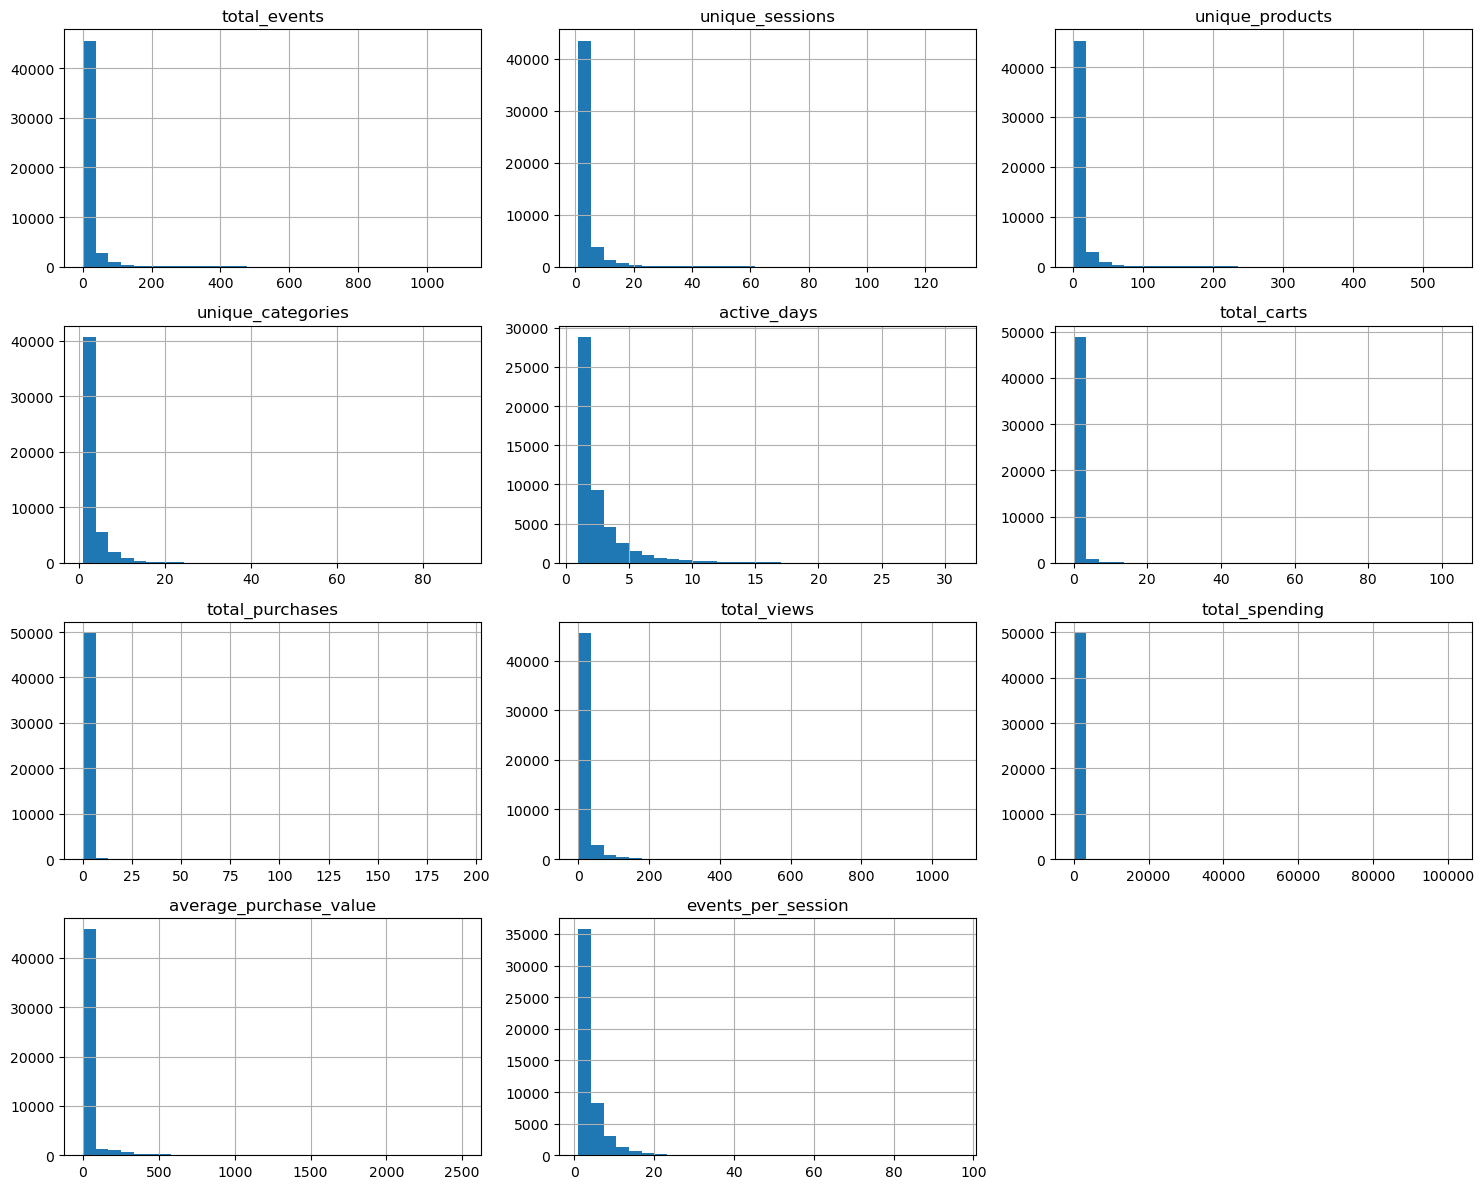

In [112]:
customer_features[feature_columns].hist(bins=30, figsize=(15, 12))
plt.tight_layout()
plt.show()

In [113]:
correlation_matrix = customer_features[feature_columns].corr()
correlation_matrix.round(2)

,total_events,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
total_events,1.00,0.82,0.92,0.69,0.73,0.36,0.37,1.00,0.24,0.16,0.42
unique_sessions,0.82,1.00,0.73,0.62,0.89,0.38,0.37,0.81,0.26,0.19,0.13
unique_products,0.92,0.73,1.00,0.81,0.69,0.18,0.19,0.93,0.10,0.10,0.46
unique_categories,0.69,0.62,0.81,1.00,0.64,0.15,0.17,0.69,0.08,0.07,0.32
active_days,0.73,0.89,0.69,0.64,1.00,0.32,0.31,0.72,0.22,0.18,0.14
total_carts,0.36,0.38,0.18,0.15,0.32,1.00,0.69,0.28,0.50,0.30,0.12
total_purchases,0.37,0.37,0.19,0.17,0.31,0.69,1.00,0.29,0.76,0.30,0.08
total_views,1.00,0.81,0.93,0.69,0.72,0.28,0.29,1.00,0.18,0.13,0.42
total_spending,0.24,0.26,0.10,0.08,0.22,0.50,0.76,0.18,1.00,0.40,0.04
average_purchase_value,0.16,0.19,0.10,0.07,0.18,0.30,0.30,0.13,0.40,1.00,0.08


Customer features are strongly right-skewed, with most users showing low activity and a small number showing very high engagement or spending.

Dealing with redundant feature

In [115]:
customer_model = customer_features.drop(columns=["user_id", "total_events"]).copy()
customer_model.head()

,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
0,1,1,1,1,0,0,2,0.0,0.0,2.0
1,1,1,1,1,0,0,1,0.0,0.0,1.0
2,2,2,1,1,0,0,2,0.0,0.0,1.0
3,5,7,3,3,0,0,17,0.0,0.0,3.4
4,2,1,1,1,0,0,2,0.0,0.0,1.0


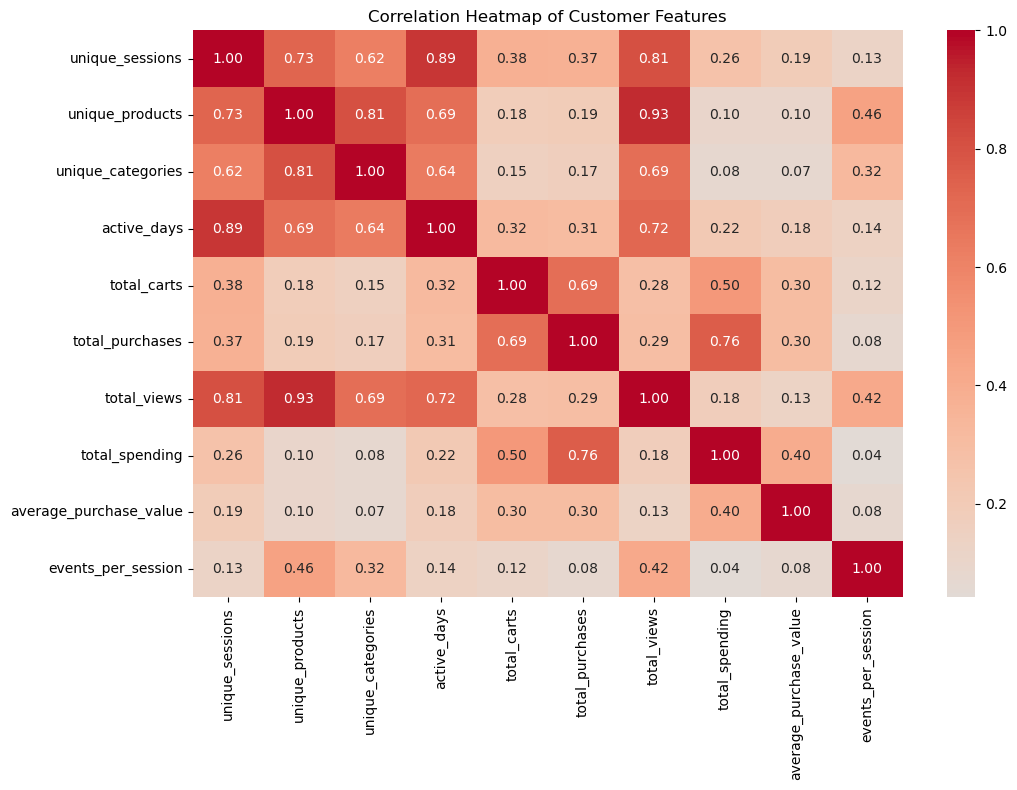

In [116]:
import seaborn as sns
plt.figure(figsize=(11, 8))
sns.heatmap(customer_model.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Customer Features")
plt.tight_layout()
plt.show()

The correlation heatmap was used to identify strongly related features and avoid giving redundant variables excessive influence in clustering.

In [131]:
outlier_summary = []

for column in customer_model.columns:
    Q1 = customer_model[column].quantile(0.25)
    Q3 = customer_model[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = customer_model[(customer_model[column] < lower_bound) | (customer_model[column] > upper_bound)]   
    outlier_summary.append({"Feature": column, "Outliers": len(outliers), "Percentage": len(outliers) / len(customer_model) * 100})

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Outliers,Percentage
0,unique_sessions,5174,10.348
1,unique_products,5023,10.046
2,unique_categories,3791,7.582
3,active_days,7267,14.534
4,total_carts,5620,11.240
5,total_purchases,5679,11.358
6,total_views,5568,11.136
7,total_spending,5679,11.358
8,average_purchase_value,5679,11.358
9,events_per_session,2845,5.690


Applying log transformation

In [117]:
customer_log = np.log1p(customer_model)
customer_log.head()

,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
0,0.693147,0.693147,0.693147,0.693147,0.0,0.0,1.098612,0.0,0.0,1.098612
1,0.693147,0.693147,0.693147,0.693147,0.0,0.0,0.693147,0.0,0.0,0.693147
2,1.098612,1.098612,0.693147,0.693147,0.0,0.0,1.098612,0.0,0.0,0.693147
3,1.791759,2.079442,1.386294,1.386294,0.0,0.0,2.890372,0.0,0.0,1.481605
4,1.098612,0.693147,0.693147,0.693147,0.0,0.0,1.098612,0.0,0.0,0.693147


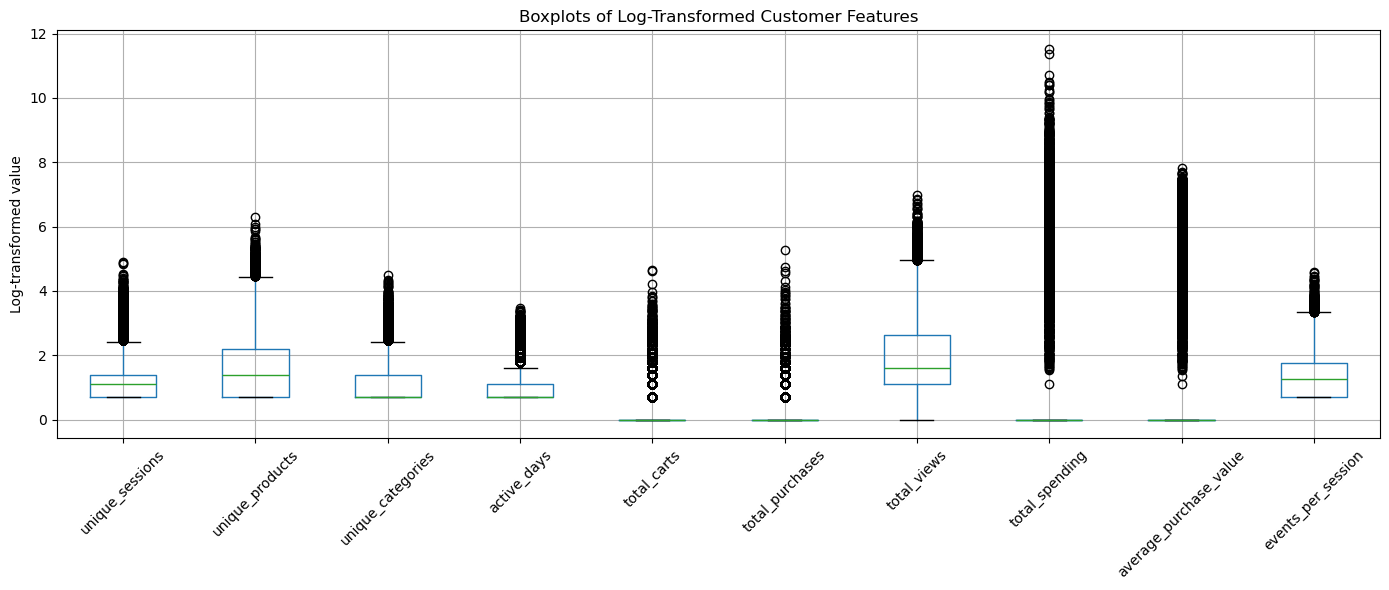

In [118]:
plt.figure(figsize=(14, 6))
customer_log.boxplot(rot=45)
plt.title("Boxplots of Log-Transformed Customer Features")
plt.ylabel("Log-transformed value")
plt.tight_layout()
plt.show()

A log transformation was applied to reduce extreme right-skewness while retaining zero values.

In [119]:
log_skewness = customer_log.skew().sort_values(ascending=False)
log_skewness

total_purchases           4.000381
total_carts               3.770139
total_spending            2.726790
average_purchase_value    2.646218
unique_categories         1.625479
active_days               1.541571
unique_sessions           1.491684
unique_products           0.990620
events_per_session        0.852448
total_views               0.844617
dtype: float64

Comparing distributions after transformation

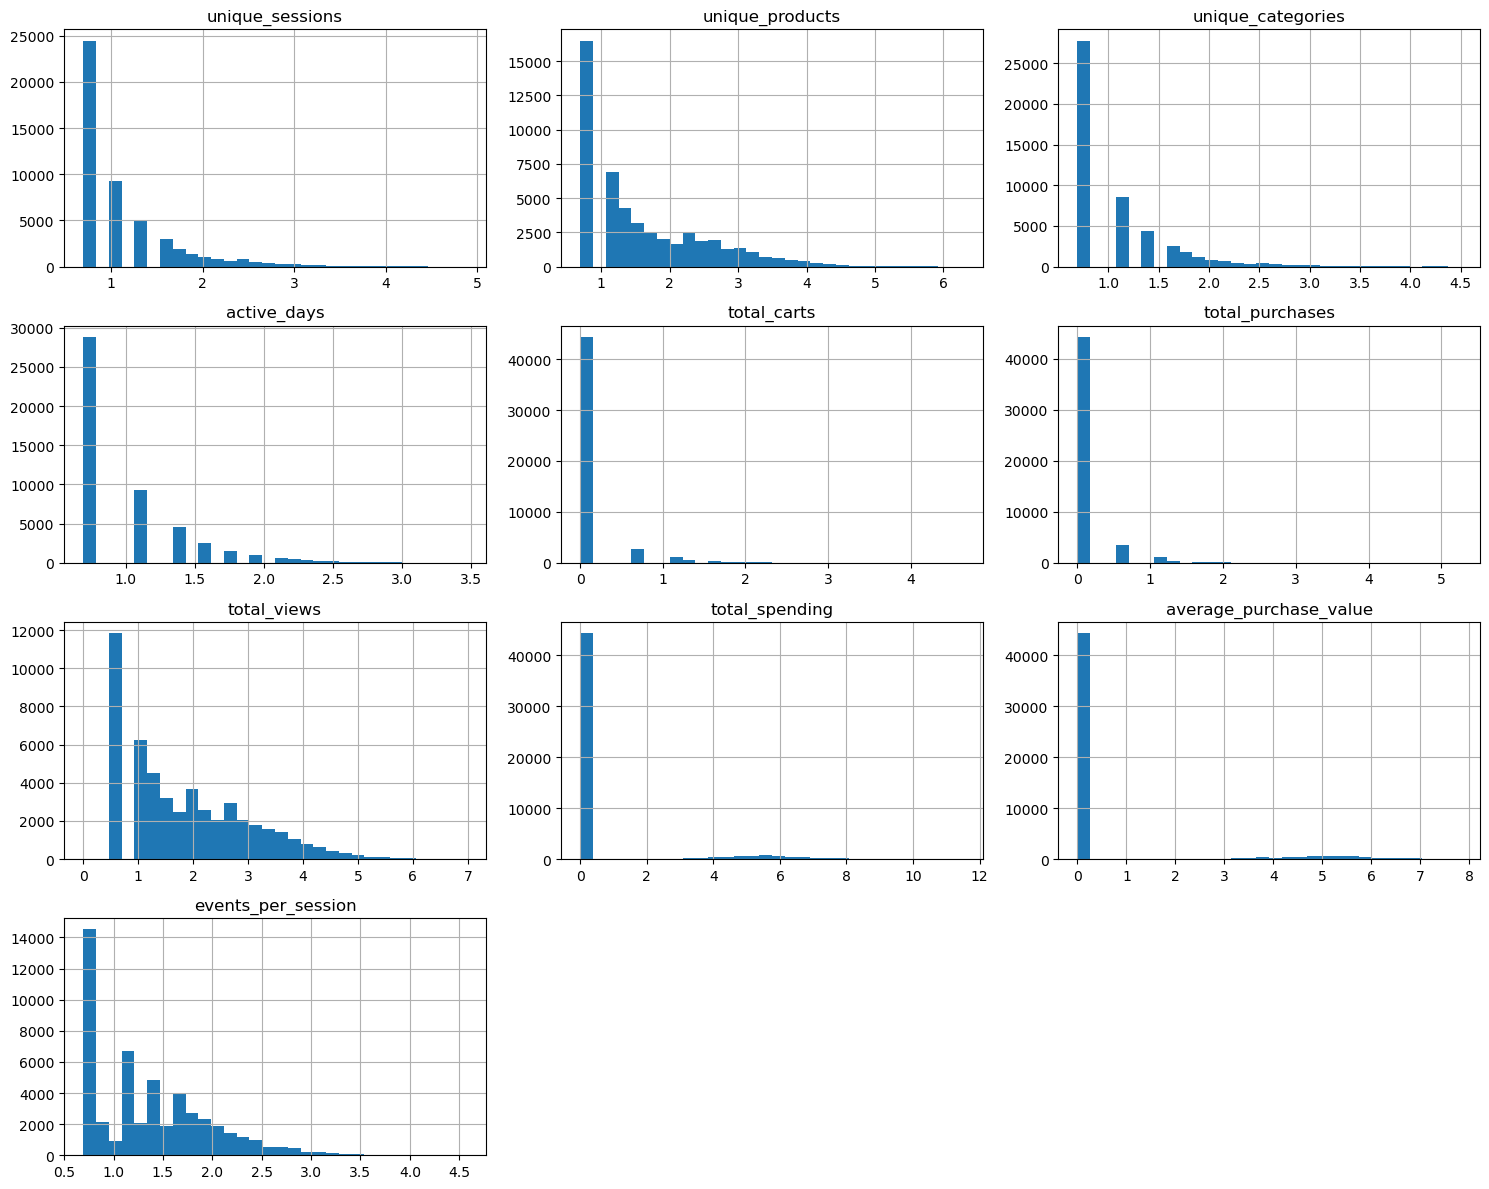

In [120]:
customer_log.hist(bins=30, figsize=(15, 12))
plt.tight_layout()
plt.show()

Standardizing the variables

In [121]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
customer_scaled = scaler.fit_transform(customer_log)

In [122]:
customer_scaled = pd.DataFrame(customer_scaled, columns=customer_log.columns, index=customer_log.index)
customer_scaled.head()

,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
0,-0.764941,-0.964159,-0.696325,-0.694026,-0.31574,-0.317353,-0.724866,-0.346526,-0.349255,-0.408790
1,-0.764941,-0.964159,-0.696325,-0.694026,-0.31574,-0.317353,-1.092190,-0.346526,-0.349255,-1.070029
2,-0.089582,-0.530868,-0.696325,-0.694026,-0.31574,-0.317353,-0.724866,-0.346526,-0.349255,-1.070029
3,1.064952,0.517274,0.579772,0.821033,-0.31574,-0.317353,0.898348,-0.346526,-0.349255,0.215800
4,-0.089582,-0.964159,-0.696325,-0.694026,-0.31574,-0.317353,-0.724866,-0.346526,-0.349255,-1.070029


In [123]:
customer_scaled.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
unique_sessions,0.0,1.0,-0.765,6.214
unique_products,0.0,1.0,-0.964,5.024
unique_categories,-0.0,1.0,-0.696,6.312
active_days,0.0,1.0,-0.694,5.366
total_carts,-0.0,1.0,-0.316,11.417
total_purchases,-0.0,1.0,-0.317,14.594
total_views,0.0,1.0,-1.720,4.602
total_spending,0.0,1.0,-0.347,5.996
average_purchase_value,0.0,1.0,-0.349,4.367
events_per_session,0.0,1.0,-1.070,5.260


StandardScaler was used so features measured on different scales contribute more equally to K-means clustering.

In [124]:
log_skewness

total_purchases           4.000381
total_carts               3.770139
total_spending            2.726790
average_purchase_value    2.646218
unique_categories         1.625479
active_days               1.541571
unique_sessions           1.491684
unique_products           0.990620
events_per_session        0.852448
total_views               0.844617
dtype: float64

Log transformation reduced extreme skewness, and StandardScaler standardized all features to comparable scales for clustering.

In [125]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

inertia_values = []
silhouette_scores = []
davies_bouldin_scores = []

k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(customer_scaled)
    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(customer_scaled, labels))
    davies_bouldin_scores.append(davies_bouldin_score(customer_scaled, labels))
print("Completed cluster evaluation.")

Completed cluster evaluation.


In [126]:
cluster_metrics = pd.DataFrame({"k": list(k_values), "Inertia": inertia_values, "Silhouette Score": silhouette_scores, "Davies-Bouldin Index": davies_bouldin_scores})
cluster_metrics

,k,Inertia,Silhouette Score,Davies-Bouldin Index
0,2,312514.027994,0.502431,1.187023
1,3,204099.304033,0.473866,0.992032
2,4,172552.135776,0.408275,1.081335
3,5,145708.351818,0.409397,1.189427
4,6,130565.193588,0.417237,1.195642
5,7,119572.988588,0.418762,1.204907
6,8,110657.635063,0.382288,1.174409


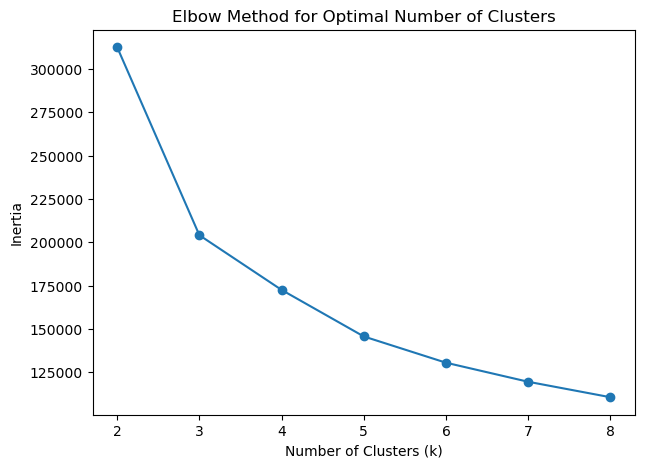

In [127]:
plt.figure(figsize=(7, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal Number of Clusters")

plt.show()

The elbow method compares within-cluster variation across different values of \(k\).

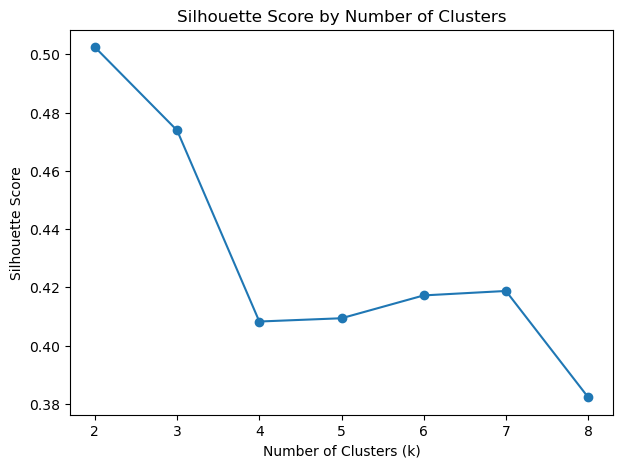

In [128]:
plt.figure(figsize=(7, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.show()

Higher silhouette scores indicate better-defined and more separated clusters.

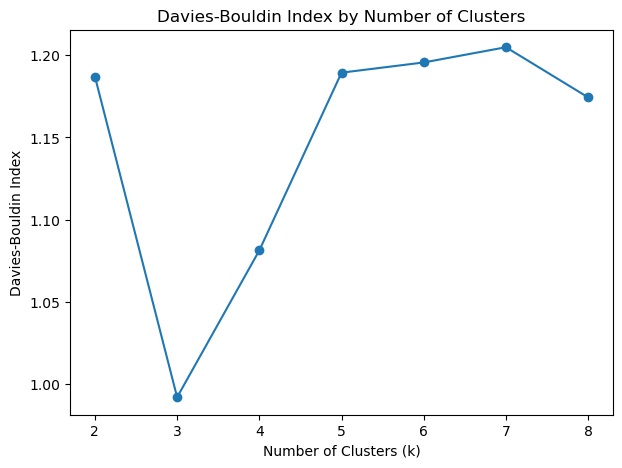

In [129]:
plt.figure(figsize=(7, 5))

plt.plot(list(k_values), davies_bouldin_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index by Number of Clusters")

plt.show()

Lower Davies–Bouldin values indicate more compact and distinct clusters.

### Optimal Number of Clusters

Three clusters were selected because k = 3 produced the lowest Davies-Bouldin Index, maintained a strong silhouette score, and showed a clear reduction in inertia.

### Final K Means Model

In [132]:
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = final_kmeans.fit_predict(customer_scaled)

The final K-means model was fitted using three clusters based on the evaluation results.

In [133]:
customer_features["cluster"] = cluster_labels
customer_features.head()

,user_id,total_events,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session,cluster
0,287873449,2,1,1,1,1,0,0,2,0.0,0.0,2.0,1
1,311511468,1,1,1,1,1,0,0,1,0.0,0.0,1.0,1
2,340362178,2,2,2,1,1,0,0,2,0.0,0.0,1.0,1
3,359660585,17,5,7,3,3,0,0,17,0.0,0.0,3.4,0
4,365369538,2,2,1,1,1,0,0,2,0.0,0.0,1.0,1


In [134]:
cluster_counts = customer_features["cluster"].value_counts().sort_index()
cluster_percentages = (customer_features["cluster"].value_counts(normalize=True).sort_index() * 100)
cluster_summary = pd.DataFrame({"Customers": cluster_counts, "Percentage": cluster_percentages})
cluster_summary

,Customers,Percentage
cluster,,
0,13403,26.806
1,31145,62.290
2,5452,10.904


In [135]:
cluster_profile = customer_features.groupby("cluster")[
    [
        "unique_sessions",
        "unique_products",
        "unique_categories",
        "active_days",
        "total_carts",
        "total_purchases",
        "total_views",
        "total_spending",
        "average_purchase_value",
        "events_per_session"
    ]
].mean().round(2)

cluster_profile

,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
cluster,,,,,,,,,,
0,5.11,16.82,4.75,3.46,0.21,0.00,28.30,0.04,0.04,6.85
1,1.40,2.07,1.28,1.22,0.03,0.01,2.87,0.25,0.25,2.19
2,7.36,17.43,4.58,4.12,2.10,2.31,37.41,742.10,286.31,5.65


In [136]:
cluster_median = customer_features.groupby("cluster")[
    [
        "unique_sessions",
        "unique_products",
        "unique_categories",
        "active_days",
        "total_carts",
        "total_purchases",
        "total_views",
        "total_spending",
        "average_purchase_value",
        "events_per_session"
    ]
].median().round(2)

cluster_median

,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
cluster,,,,,,,,,,
0,4.0,11.0,4.0,3.0,0.0,0.0,18.0,0.00,0.00,5.0
1,1.0,1.0,1.0,1.0,0.0,0.0,2.0,0.00,0.00,1.5
2,5.0,8.0,3.0,3.0,1.0,1.0,17.0,256.41,179.28,4.6


Cluster profiles were compared using both mean and median values to understand customer behavior.

### Cluster Interpretation

**Cluster 0 – Engaged Browsers:** Customers in this group browse frequently and explore many products but rarely complete purchases.

**Cluster 1 – Low-Engagement Visitors:** These customers show the lowest visit frequency, browsing activity, cart activity, and purchasing behavior.

**Cluster 2 – High-Value Customers:** These customers have the highest purchasing activity, spending, and overall engagement.

In [137]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(customer_scaled)
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"])
pca_df["cluster"] = cluster_labels

In [138]:
print("PC1 explained variance:", pca.explained_variance_ratio_[0])
print("PC2 explained variance:", pca.explained_variance_ratio_[1])
print("Total explained variance:", pca.explained_variance_ratio_.sum())

PC1 explained variance: 0.552416087071062
PC2 explained variance: 0.24245928108983333
Total explained variance: 0.7948753681608953


PCA reduced the customer features to two principal components for visualization.

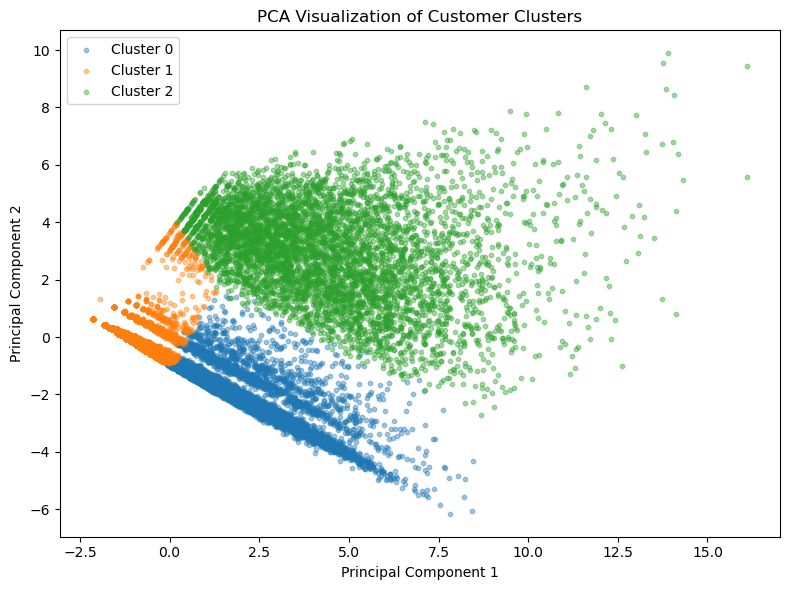

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for cluster in sorted(pca_df["cluster"].unique()):
    cluster_data = pca_df[pca_df["cluster"] == cluster]
    plt.scatter(cluster_data["PC1"], cluster_data["PC2"], label=f"Cluster {cluster}", alpha=0.4, s=10)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Customer Clusters")
plt.legend()
plt.tight_layout()
plt.show()

### PCA Interpretation

The first two principal components explained 79.49% of the total variance, providing a clear two-dimensional view of the three customer segments.

Creating a cluster comparison chart

In [140]:
scaled_with_cluster = customer_scaled.copy()
scaled_with_cluster["cluster"] = cluster_labels
scaled_cluster_profile = scaled_with_cluster.groupby("cluster").mean()
scaled_cluster_profile

,unique_sessions,unique_products,unique_categories,active_days,total_carts,total_purchases,total_views,total_spending,average_purchase_value,events_per_session
cluster,,,,,,,,,,
0,0.779244,1.093306,0.909906,0.795420,-0.047665,-0.308045,1.048068,-0.340751,-0.342956,0.842288
1,-0.521932,-0.602325,-0.504292,-0.507058,-0.264823,-0.306948,-0.619836,-0.335970,-0.337714,-0.484922
2,1.065918,0.753084,0.643927,0.941177,1.630002,2.510753,0.964331,2.756945,2.772333,0.699505


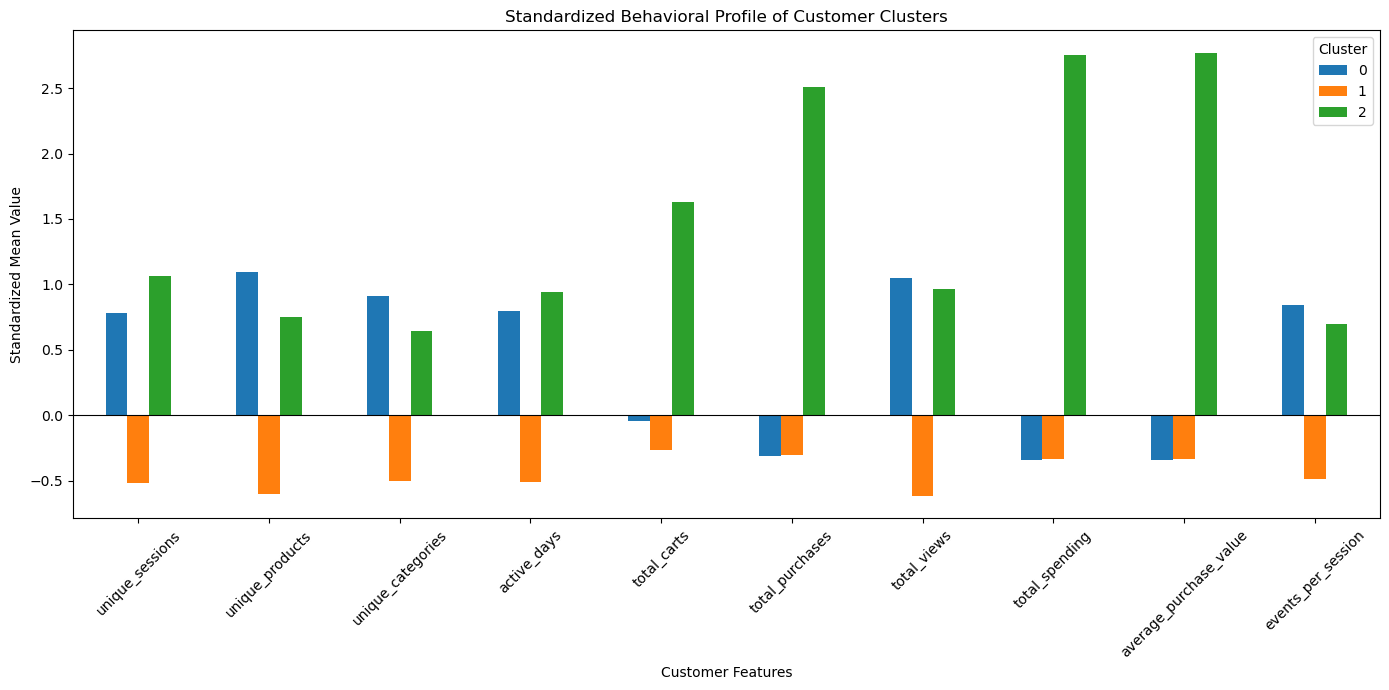

In [141]:
scaled_cluster_profile.T.plot(kind="bar", figsize=(14, 7))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Standardized Behavioral Profile of Customer Clusters")
plt.xlabel("Customer Features")
plt.ylabel("Standardized Mean Value")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

Standardized cluster profiles were compared to show how each segment differs from the overall customer average.

### Clustering Metrics

The three-cluster solution achieved a silhouette score of 0.474 and a Davies-Bouldin Index of 0.992, indicating useful cluster separation with some overlap between groups.

Creating a cluster-size chart

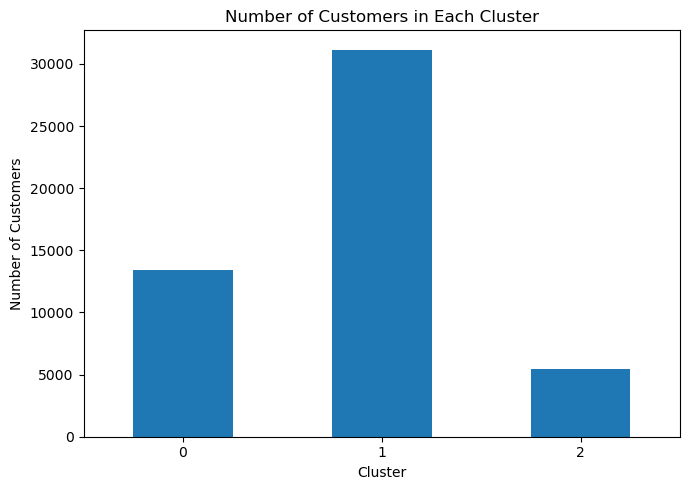

In [142]:
plt.figure(figsize=(7, 5))
cluster_summary["Customers"].plot(kind="bar")
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Cluster 1 contains most customers, while Cluster 2 is the smallest segment.

### Business Recommendations

Cluster 0 can be targeted with personalized recommendations and conversion-focused promotions. Cluster 1 may benefit from re-engagement campaigns and introductory offers. Cluster 2 should be supported through loyalty rewards, retention strategies, and exclusive promotions.

In [143]:
cluster_names = {0: "Engaged Browsers", 1: "Low-Engagement Visitors", 2: "High-Value Customers"}
customer_features["segment"] = customer_features["cluster"].map(cluster_names)
customer_features[["user_id", "cluster", "segment"]].head()

,user_id,cluster,segment
0,287873449,1,Low-Engagement Visitors
1,311511468,1,Low-Engagement Visitors
2,340362178,1,Low-Engagement Visitors
3,359660585,0,Engaged Browsers
4,365369538,1,Low-Engagement Visitors


### Reflection

The main challenges were managing a large event-based dataset, handling strong skewness and outliers, and selecting clusters without predefined labels. This analysis demonstrates how unsupervised learning can identify useful customer patterns from unlabeled data.

Unsupervised learning can also be applied to fraud detection, patient segmentation, document grouping, anomaly detection, and recommendation systems.